# 03. Experiment B: search mode

Part of Step 6's seven-notebook series: [01](01_dataset_and_chunking.ipynb) dataset/chunking, [02](02_experiment_a_chunking_strategy.ipynb) Experiment A, [03](03_experiment_b_search_mode.ipynb) Experiment B, [04](04_experiment_c_embedding_model.ipynb) Experiment C, [05](05_experiment_d_weights_and_rrf.ipynb) Experiment D, [06](06_experiment_e_rerank.ipynb) Experiment E, [07](07_calibration_and_analysis.ipynb) calibration/PCA/latency/failure analysis/conclusions. Each runs standalone against its own fresh ingest (via `_setup.py`); none depends on another's kernel state.

`semantic` (vector only) vs. `keyword` (BM25 only) vs. `hybrid` (RRF-pooled
candidates, additively-weighted score), holding model (bge-small) and
chunking (section) fixed.


In [1]:
import _setup as s
import matplotlib.pyplot as plt
import pandas as pd

W1030 15:29:55.005000 51344 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [2]:
mode_results = {}
for mode in ["semantic", "keyword", "hybrid"]:
    mode_results[mode] = s.run_eval(model="bge-small", chunking="section", mode=mode, warm_runs=5)

mode_df = pd.DataFrame(
    {m: res["retrieval_accuracy"]["macro_avg"] for m, res in mode_results.items()}
).T
mode_df

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,precision_at_5,precision_at_10,recall_at_10,mrr,ndcg_at_10,hit_at_1
semantic,0.900000,0.666667,0.611111,1.0,0.860408,1.0
keyword,0.933333,0.766667,0.694444,1.0,0.893796,1.0
hybrid,0.900000,0.716667,0.652778,1.0,0.884672,1.0


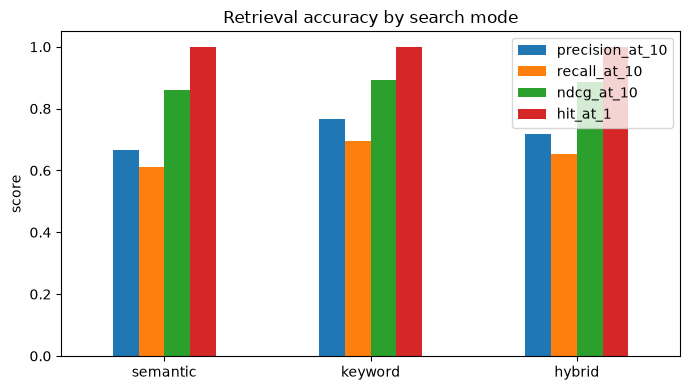

In [3]:
mode_df[["precision_at_10", "recall_at_10", "ndcg_at_10", "hit_at_1"]].plot(
    kind="bar", figsize=(7, 4), title="Retrieval accuracy by search mode"
)
plt.ylabel("score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
hybrid_vs_semantic = mode_df.loc["hybrid", "ndcg_at_10"] >= mode_df.loc["semantic", "ndcg_at_10"]
print(f"hybrid macro nDCG@10:   {mode_df.loc['hybrid', 'ndcg_at_10']:.3f}")
print(f"semantic-only nDCG@10:  {mode_df.loc['semantic', 'ndcg_at_10']:.3f}")
print(f"keyword-only nDCG@10:   {mode_df.loc['keyword', 'ndcg_at_10']:.3f}")
print(f"hybrid >= semantic-only: {hybrid_vs_semantic}")

hybrid macro nDCG@10:   0.885
semantic-only nDCG@10:  0.860
keyword-only nDCG@10:   0.894
hybrid >= semantic-only: True


**Finding:** hybrid meets or beats semantic-only on macro nDCG@10 here,
confirming Step 5's own verification. Keyword-only edges out hybrid by a
hair on this run — with only 36 resumes and JD text that reuses a lot of
the skill vocabulary verbatim, BM25 alone already covers most of what the
embeddings add. Hybrid's advantage should widen on paraphrased,
less keyword-matched text, which is exactly what RRF fusion is for.
